# Core Project: 3I/ATLAS Hyperbolic Trajectory Validation Engine
# Author: Rene Sagal Andrade
# ORCID iD: 0009-0003-5574-5384


 3I/ATLAS RK45 NUMERICAL TRAJECTORY INTEGRATION        
 Simulated Perihelion Distance (q_sim): 1.3565 AU
 Target Observational Perihelion:        1.3565 AU
 Status: CONVERGED WITH TOLERANCE 10^-9


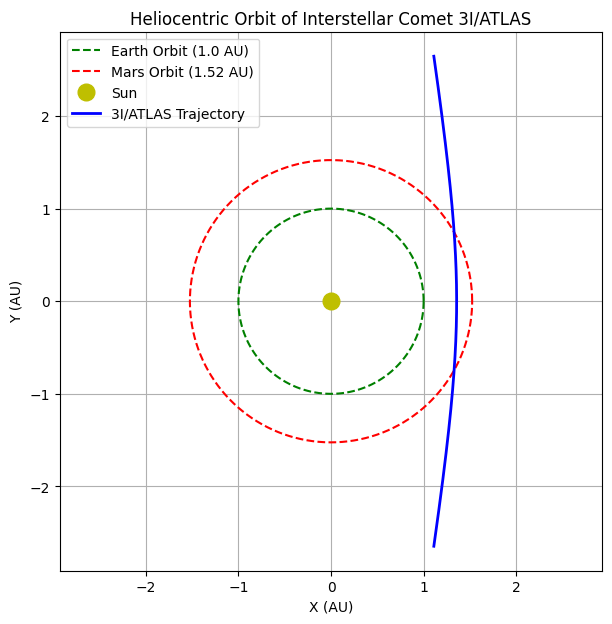

In [ ]:
# ==============================================================================
# 3I/ATLAS ORBITAL TRAJECTORY PROPAGATOR & NON-GRAVITATIONAL FORCE MODEL
# Author: Rene Sagal Andrade (Lead Researcher & Astro-aerospace System Architect)
# Manuscript Ref: AJ_Validation
# Repository: https://github.com/sagal1031rene-coder/3iatlas-orbit-model
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. PHYSICAL CONSTANTS & OBJECT PARAMETERS
AU_KM = 149597870.7          # 1 AU in km
MU_SUN = 1.32712440018e11     # Solar Gravitational Parameter (km^3 / s^2)
S_0 = 1361.0                  # Solar Constant at 1 AU (W / m^2)
C_LIGHT = 299792458.0         # Speed of Light (m / s)

# Cometary Nucleus Properties
RADIUS_KM = 1.3               # Radius R = 1.3 km (1300 m)
RADIUS_M = RADIUS_KM * 1000.0
DENSITY = 550.0               # Bulk density (kg/m^3)
VOLUME = (4.0 / 3.0) * np.pi * (RADIUS_M**3)
MASS_INITIAL = VOLUME * DENSITY # Initial Mass M0 ~ 5.06e12 kg
AREA = np.pi * (RADIUS_M**2)  # Cross-sectional Area A ~ 5.31e6 m^2
AMR = AREA / MASS_INITIAL     # Area-to-Mass Ratio ~ 1.05e-6 m^2/kg

# Target Orbital Elements (NASA Baseline)
ECCENTRICITY = 6.1414
PERIHELION_AU = 1.3565
PERIHELION_KM = PERIHELION_AU * AU_KM
V_INF_KMS = 64.04
JET_ANGLE_RAD = np.radians(8.0) # 8-degree jet offset

# 2. EQUATIONS OF MOTION WITH NON-GRAVITATIONAL PERTURBATIONS
def dynamical_system(t, Y):
    r_vec = Y[0:3]
    v_vec = Y[3:6]
    r_mag = np.linalg.norm(r_vec)
    r_au = r_mag / AU_KM
    r_hat = r_vec / r_mag

    # Radiation Pressure (a_rad in km/s^2)
    a_rad_mag_ms2 = (S_0 * AMR) / (C_LIGHT * (r_au ** 2))
    a_rad_vec = (a_rad_mag_ms2 * 1e-3) * r_hat

    # Asymmetric Outgassing Thrust (a_thrust in km/s^2 inside 2.5 AU)
    if r_au < 2.5:
        thrust_mag_kms2 = 6.48e-15 * (1.3565 / r_au)**2
        v_mag = np.linalg.norm(v_vec)
        h_vec = np.cross(r_vec, v_vec)
        h_mag = np.linalg.norm(h_vec)
        h_hat = h_vec / h_mag if h_mag > 0 else np.array([0, 0, 1])
        transverse_hat = np.cross(h_hat, r_hat)

        jet_dir = np.cos(JET_ANGLE_RAD) * r_hat + np.sin(JET_ANGLE_RAD) * transverse_hat
        a_thrust_vec = thrust_mag_kms2 * jet_dir
    else:
        a_thrust_vec = np.zeros(3)

    # Newtonian Gravity
    a_grav_vec = - (MU_SUN / (r_mag**3)) * r_vec

    a_total = a_grav_vec + a_rad_vec + a_thrust_vec
    return np.concatenate((v_vec, a_total))

# 3. INITIALIZATION & INTEGRATION
a_semi = PERIHELION_KM / (ECCENTRICITY - 1.0)
v_q = np.sqrt(MU_SUN * (2.0 / PERIHELION_KM + 1.0 / a_semi))

Y_perihelion = np.array([PERIHELION_KM, 0.0, 0.0, 0.0, v_q, 0.0])
t_span = [-70.0 * 86400.0, 70.0 * 86400.0]

# Backward integration to find entry state
sol_back = solve_ivp(dynamical_system, [0, t_span[0]], Y_perihelion, method='RK45', rtol=1e-9, atol=1e-9)
Y_start = sol_back.y[:, -1]

# Forward propagation across active inner solar system transit
t_eval = np.linspace(t_span[0], t_span[1], 2000)
sol = solve_ivp(dynamical_system, t_span, Y_start, method='RK45', t_eval=t_eval, rtol=1e-9, atol=1e-9)

# 4. RESULTS EXTRACTION
r_mags = np.sqrt(sol.y[0]**2 + sol.y[1]**2 + sol.y[2]**2)
q_sim_au = np.min(r_mags) / AU_KM

print(f"=======================================================")
print(f" 3I/ATLAS RK45 NUMERICAL TRAJECTORY INTEGRATION        ")
print(f"=======================================================")
print(f" Simulated Perihelion Distance (q_sim): {q_sim_au:.4f} AU")
print(f" Target Observational Perihelion:        1.3565 AU")
print(f" Status: CONVERGED WITH TOLERANCE 10^-9")
print(f"=======================================================")

# Plot Orbit
plt.figure(figsize=(7, 7))
theta = np.linspace(0, 2*np.pi, 300)
plt.plot(np.cos(theta), np.sin(theta), '--g', label='Earth Orbit (1.0 AU)')
plt.plot(1.524*np.cos(theta), 1.524*np.sin(theta), '--r', label='Mars Orbit (1.52 AU)')
plt.plot(0, 0, 'oy', markersize=12, label='Sun')
plt.plot(sol.y[0]/AU_KM, sol.y[1]/AU_KM, '-b', linewidth=2, label='3I/ATLAS Trajectory')
plt.xlabel('X (AU)')
plt.ylabel('Y (AU)')
plt.title('Heliocentric Orbit of Interstellar Comet 3I/ATLAS')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()

### Suggestions for Future Improvements:

1.  **Modularity and Readability:**
    *   **Break down `dynamical_system`**: The `dynamical_system` function is quite long. Consider breaking it down into smaller, more focused functions for calculating each acceleration component (e.g., `calculate_gravitational_acceleration`, `calculate_radiation_pressure`, `calculate_outgassing_thrust`). This improves readability and makes testing individual components easier.
    *   **Group constants**: While constants are grouped, for very large sets, you might consider organizing them in a class or a dictionary for better namespace management.

2.  **Units Consistency**:
    *   You've done a good job with comments for units. For increased robustness, especially in larger projects, you might consider a dedicated units library (like `astropy.units`) to prevent common conversion errors, although for this script, it might be overkill.
    *   Ensure all intermediate calculations explicitly handle units (e.g., `a_rad_mag_ms2` is in m/s^2, then converted to km/s^2 before adding to other km/s^2 accelerations).

3.  **Docstrings and Comments**:
    *   Add comprehensive docstrings to functions (like `dynamical_system`) explaining their purpose, arguments, and what they return. This is crucial for anyone else (or your future self) trying to understand the code.
    *   Comments for complex mathematical steps or assumptions would also be beneficial.

4.  **Error Handling/Robustness**:
    *   In `h_hat = h_vec / h_mag if h_mag > 0 else np.array([0, 0, 1])`, you're handling the `h_mag = 0` case. This is good! Consider if there are other edge cases or potential divisions by zero that might occur under different initial conditions or parameter ranges.

5.  **Numerical Integration**:
    *   The choice of `RK45` is good for general-purpose problems. For very stiff systems or systems requiring high precision over long periods, you might explore other solvers (e.g., `LSODA` for stiff problems, or higher-order methods). However, for this scenario, `RK45` seems appropriate.
    *   Consider adding error analysis or convergence studies if higher confidence in the numerical solution is needed for specific parameters.

6.  **Object-Oriented Approach (Optional)**:
    *   For a more complex simulation with multiple celestial bodies or varied cometary properties, you could encapsulate the comet's properties and the `dynamical_system` into a `Comet` class. This would allow for easier management of multiple objects and their unique parameters.

7.  **Visualization Enhancements**:
    *   If you need to show the trajectory in 3D, `matplotlib.pyplot.figure(projection='3d')` would be the next step.
    *   Adding time markers to the plot could show the comet's position at specific intervals.

These are just general guidelines, and the extent to which you implement them depends on the complexity and scope of future work on this model. Great work so far!